A1 — Import libraries
These libraries read data, calculate statistics and create graphs.

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


A2 — Set the dataset path
The dataset is named data.csv and is stored in the same project folder as this notebook. No file search is needed.

In [5]:
DATA_PATH = "data.csv"
print("Dataset:", DATA_PATH)

Dataset: data.csv


A3 — Read a preview
Show the first five posts without loading the entire dataset.

In [8]:
preview = pd.read_csv(DATA_PATH, nrows=5, low_memory=False)
display(preview)

,ioCountry,postid,post_text,application_name,post_language,in_reply_to_postid,in_reply_to_accountid,post_time,accountid,account_profile_description,follower_count,following_count,account_creation_date,is_repost,reposted_accountid,reposted_postid,hashtags,urls,account_mentions,is_control
0,ecuador,0bafe020a260495bee38b98fde83668d924454019b,Vamos a cambiar la forma de hacer comunicación...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,NaN,NaN,NaN,2010-03-13 02:52:00,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,"#Periodismo, #RelacionesPúblicas, #Comunicac...",1528,2619,2010-03-11,False,NaN,NaN,[],[],[],False
1,ecuador,608fba51f2460c7f1ca527dfc48de2bc858d4ad201,"Damos servicio de manejo de prensa, elaboració...",2727201c363b6fc4afe259ba4094ae0c49cb4df224,NaN,NaN,NaN,2010-03-13 03:08:00,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,"#Periodismo, #RelacionesPúblicas, #Comunicac...",1528,2619,2010-03-11,False,NaN,NaN,[],[],[],False
2,ecuador,514b2c38b26e240cac85382be74ed7d61a02468ac1,@db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302 Bu...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,NaN,f29b32f8dbaa1e0f00152decbcc2bd93dddc740464,db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302,2010-03-13 15:26:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,NaN,35,215,2010-01-28,False,NaN,NaN,[],[],['db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302'],False
3,ecuador,e82a816068e88387d19430348f0420b040e0d11b4e,"Mario, debemos denuciar que en los poderes pub...",2727201c363b6fc4afe259ba4094ae0c49cb4df224,NaN,NaN,NaN,2010-03-13 15:32:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,NaN,35,215,2010-01-28,False,NaN,NaN,[],[],[],False
4,ecuador,13ed6aaeec4fffaf840f1c42ff88f5ab2cb324be64,Tambien debemos estar claro que la oposición e...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,NaN,NaN,NaN,2010-03-13 15:35:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,NaN,35,215,2010-01-28,False,NaN,NaN,[],[],[],False


A4 — Describe the 20 variables
This table explains the meaning of each field, following the professor's dataset description.

In [6]:
meanings = {
    "ioCountry":"Country responsible for the information operation",
    "postid":"Anonymized post ID", "post_text":"Post text",
    "application_name":"Publishing application", "post_language":"Post language",
    "in_reply_to_postid":"Replied-to post ID", "in_reply_to_accountid":"Replied-to account ID",
    "post_time":"Publication time", "accountid":"Anonymized author ID",
    "account_profile_description":"Account biography", "follower_count":"Follower count",
    "following_count":"Following count", "account_creation_date":"Account creation date",
    "is_repost":"Repost flag", "reposted_accountid":"Reposted account ID",
    "reposted_postid":"Reposted post ID", "hashtags":"Hashtag list",
    "urls":"URL list", "account_mentions":"Mention list",
    "is_control":"True: control; False: information operation"
}
display(pd.DataFrame(meanings.items(), columns=["Column", "Meaning"]))

,Column,Meaning
0,ioCountry,Country responsible for the information operation
1,postid,Anonymized post ID
2,post_text,Post text
3,application_name,Publishing application
4,post_language,Post language
5,in_reply_to_postid,Replied-to post ID
6,in_reply_to_accountid,Replied-to account ID
7,post_time,Publication time
8,accountid,Anonymized author ID
9,account_profile_description,Account biography


A5 — Verify the schema
Check whether the CSV contains all 20 expected columns.

In [9]:
expected = set(meanings)
actual = set(preview.columns)
print("Columns:", len(actual))
print("Missing expected:", sorted(expected - actual))
print("Unexpected:", sorted(actual - expected))
assert expected <= actual, "Some required columns are absent."

Columns: 20
Missing expected: []
Unexpected: []


A6 — Data types
Check which fields are numeric, textual or dates (dates may initially be read as text).

In [10]:
display(preview.dtypes.rename("CSV dtype").to_frame())

,CSV dtype
ioCountry,str
postid,str
post_text,str
application_name,str
post_language,float64
in_reply_to_postid,str
in_reply_to_accountid,str
post_time,str
accountid,str
account_profile_description,str


B. Full-dataset overview and data quality
The dataset may be large. We use chunks for full-data counts and a limited sample only for exploratory graphs. Never present sample statistics as full-data statistics.


B1 — Count every row and class
Count all posts, control posts and information-operation posts without a 5,000-row limit.

In [11]:
total_posts = 0
class_counts = pd.Series(dtype="int64")
for chunk in pd.read_csv(DATA_PATH, usecols=["is_control"], chunksize=100_000, dtype="string"):
    total_posts += len(chunk)
    labels = chunk["is_control"].str.strip().str.lower()
    class_counts = class_counts.add(labels.value_counts(dropna=False), fill_value=0)
print("Total posts:", total_posts)
display(class_counts.to_frame("Posts"))

Total posts: 8714356


,Posts
is_control,
false,5230077.0
is_control?,1112.0
true,3483167.0


B2 — Check class-label inconsistencies
Valid labels are true and false. Other values should be investigated.

In [12]:
invalid_labels = class_counts[~class_counts.index.isin(["true", "false"])]
print("Missing or invalid class labels:")
display(invalid_labels)

Missing or invalid class labels:


is_control
is_control?    1112.0
dtype: double[pyarrow]

B3 — Check missing values across all posts
Report both missing counts and percentages. Some empty reply/repost fields are normal when a post is not a reply/repost.

In [13]:
missing = pd.Series(0, index=preview.columns, dtype="int64")
for chunk in pd.read_csv(DATA_PATH, chunksize=100_000, dtype="string"):
    missing = missing.add(chunk.isna().sum(), fill_value=0)
missing_table = pd.DataFrame({"Count": missing, "Percent": 100 * missing / total_posts})
display(missing_table.sort_values("Percent", ascending=False).round(2))

,Count,Percent
in_reply_to_accountid,7839269,89.96
in_reply_to_postid,7828114,89.83
reposted_postid,5109181,58.63
reposted_accountid,5109181,58.63
account_profile_description,1669919,19.16
post_language,103743,1.19
follower_count,1318,0.02
following_count,1192,0.01
post_text,3,0.00
is_repost,0,0.00


B4 — Plot missing percentages
This chart makes it easy to identify fields needing attention.

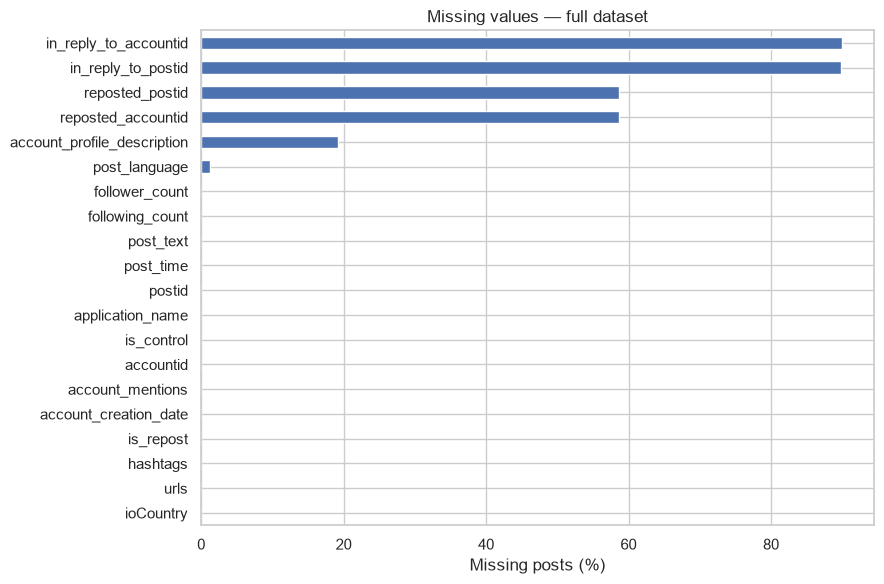

In [14]:
missing_table["Percent"].sort_values().plot.barh(figsize=(9, 6))
plt.xlabel("Missing posts (%)")
plt.title("Missing values — full dataset")
plt.tight_layout()
plt.show()

B5 — Find exact duplicated rows
This check is sample-based for speed. A full-dataset exact-duplicate check requires more memory or an external database.

In [15]:
SAMPLE_SIZE = 50_000
sample = pd.read_csv(DATA_PATH, nrows=SAMPLE_SIZE, low_memory=False)
print("Sample rows:", len(sample))
print("Exact duplicates in sample:", sample.duplicated().sum())

Sample rows: 50000
Exact duplicates in sample: 0


B6 — Check repeated post IDs
Count repeated post IDs in the sample; postid should identify a post. Repeated account IDs, however, are expected.

In [16]:
print("Repeated post IDs (sample):", sample["postid"].duplicated().sum())
print("Unique accounts (sample):", sample["accountid"].nunique())

Repeated post IDs (sample): 0
Unique accounts (sample): 951


B7 — Inspect suspicious numeric values
Negative follower/following counts are invalid. Missing or nonnumeric values also need review.

In [17]:
numeric = sample[["follower_count", "following_count"]].apply(pd.to_numeric, errors="coerce")
for col in numeric:
    print(col, "negative:", int((numeric[col] < 0).sum()),
          "missing/invalid:", int(numeric[col].isna().sum()))

follower_count negative: 1 missing/invalid: 21
following_count negative: 7 missing/invalid: 14


B8 — Check date parsing
Invalid dates may indicate errors. This uses a sample; different date formats should be investigated before any cleaning.

In [23]:
for col in ["post_time", "account_creation_date"]:
    parsed = pd.to_datetime(sample[col], errors="coerce", utc=True)
    print(col, "unparseable or missing:", parsed.isna().sum())

post_time unparseable or missing: 0
account_creation_date unparseable or missing: 0


B9 — Validate repost/reply fields
A missing reply ID is often expected for a post that is not a reply. Check examples before treating these as data-quality errors.

In [24]:
display(sample[["is_repost", "reposted_postid", "in_reply_to_postid"]].head(10))

,is_repost,reposted_postid,in_reply_to_postid
0,False,NaN,NaN
1,False,NaN,NaN
2,False,NaN,f29b32f8dbaa1e0f00152decbcc2bd93dddc740464
3,False,NaN,NaN
4,False,NaN,NaN
5,False,NaN,NaN
6,False,NaN,NaN
7,False,NaN,NaN
8,False,NaN,NaN
9,False,NaN,NaN


C. Distributions and descriptive statistics
Describe numerical and categorical variables using tables and relevant plots. The graphs in this section use a first-row sample and are exploratory.

C1 — Numeric descriptive statistics
Compare median, mean, minimum, quartiles and maximum. The median is more robust to extreme values.

In [25]:
display(numeric.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
follower_count,49979.0,2703630.70,4.284681e+08,-292406.0,519.0,963.0,3618.0,7.923488e+10
following_count,49986.0,4223760.73,5.830738e+08,-968542.0,270.0,506.0,2055.0,9.942571e+10


C2 — Visualize skewed numeric values
Follower counts may have a long right tail. Log transformation is used only for visualization here.

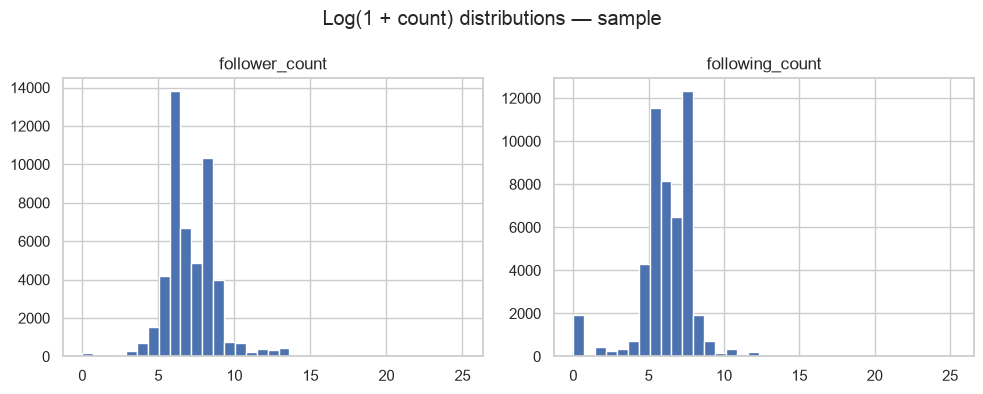

In [26]:
numeric.clip(lower=0).apply(np.log1p).hist(bins=35, figsize=(10, 4))
plt.suptitle("Log(1 + count) distributions — sample")
plt.tight_layout()
plt.show()

C3 — Identify potential numeric outliers
Use the IQR rule to flag unusual counts; do not automatically delete these accounts because high activity may be meaningful.

In [27]:
q1 = numeric.quantile(0.25)
q3 = numeric.quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
outliers = numeric.gt(upper).sum()
display(pd.DataFrame({"Upper IQR fence": upper, "Above fence": outliers}))

,Upper IQR fence,Above fence
follower_count,8266.5,5834
following_count,4732.5,2225


C4 — Country distribution (full dataset)
Count posts from each information-operation country across the entire CSV.

In [28]:
country_counts = pd.Series(dtype="int64")
for chunk in pd.read_csv(DATA_PATH, usecols=["ioCountry"], chunksize=100_000):
    country_counts = country_counts.add(chunk["ioCountry"].value_counts(), fill_value=0)
display(country_counts.sort_values(ascending=False).head(15).to_frame("Posts"))

,Posts
ioCountry,
russia_1,3650728.0
uae,1708103.0
ecuador,1470819.0
iran_1,1323023.0
iran_4,561683.0


C5 — Plot the top countries
Visualize the countries with the most posts.

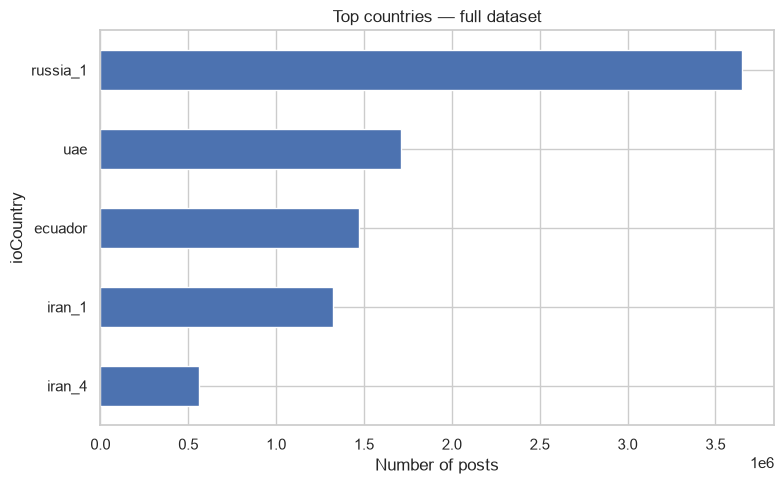

In [29]:
country_counts.nlargest(10).sort_values().plot.barh(figsize=(8, 5))
plt.xlabel("Number of posts")
plt.title("Top countries — full dataset")
plt.tight_layout()
plt.show()

C6 — Plot control vs operation classes
Class imbalance matters when comparing behavior. Counts come from the entire CSV.

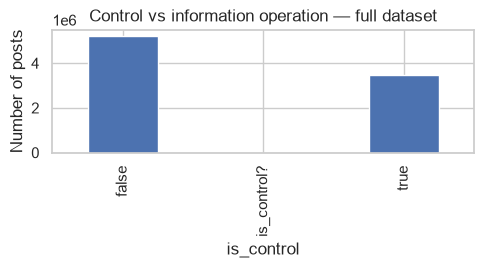

In [31]:
class_counts.sort_index().plot.bar(figsize=(5, 3))
plt.ylabel("Number of posts")
plt.title("Control vs information operation — full dataset")
plt.tight_layout()
plt.show()

C7 — Language distribution
Identify the most common languages in the exploratory sample.

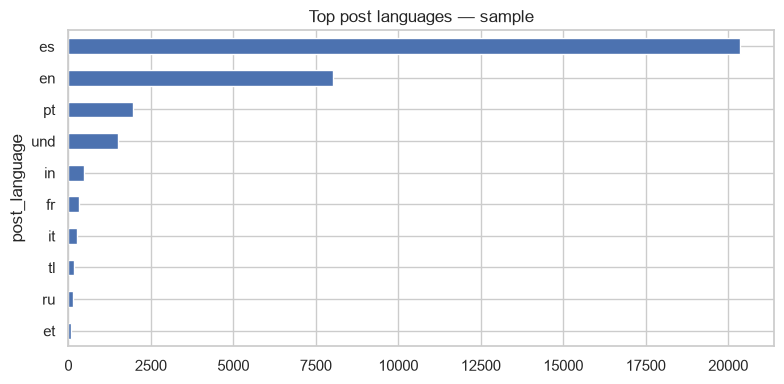

In [32]:
sample["post_language"].value_counts().head(10).sort_values().plot.barh(figsize=(8, 4))
plt.title("Top post languages — sample")
plt.tight_layout()
plt.show()

C8 — Publishing application distribution
Determine which publishing clients are common.

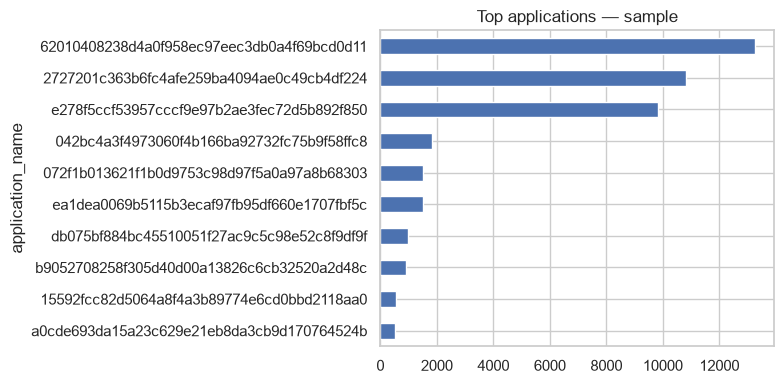

In [34]:
sample["application_name"].value_counts().head(10).sort_values().plot.barh(figsize=(8, 4))
plt.title("Top applications — sample")
plt.tight_layout()
plt.show()

C9 — Repost rates by class
Compare how often control and operation posts are reposts. This is descriptive, not proof of coordination.

In [35]:
labels = sample["is_control"].astype("string").str.lower().map({"true":"Control", "false":"Operation"})
reposts = sample["is_repost"].astype("string").str.lower().map({"true":1, "false":0})
repost_rates = pd.DataFrame({"class":labels, "repost":reposts}).groupby("class")["repost"].mean()
display((100 * repost_rates).round(2).rename("Repost rate (%)"))

class
Control      13.08
Operation    16.59
Name: Repost rate (%), dtype: float64

C10 — Plot repost rates
A bar chart makes class differences easier to interpret.

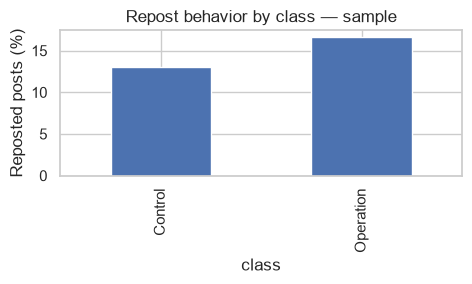

In [36]:
(100 * repost_rates).plot.bar(figsize=(5, 3))
plt.ylabel("Reposted posts (%)")
plt.title("Repost behavior by class — sample")
plt.tight_layout()
plt.show()

C11 — Monthly activity
Convert timestamps and examine activity over time.

/var/folders/q9/zj0sb7h14b1513lt554dnmy80000gn/T/ipykernel_60367/814654116.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly = post_dates.dt.to_period("M").value_counts().sort_index()


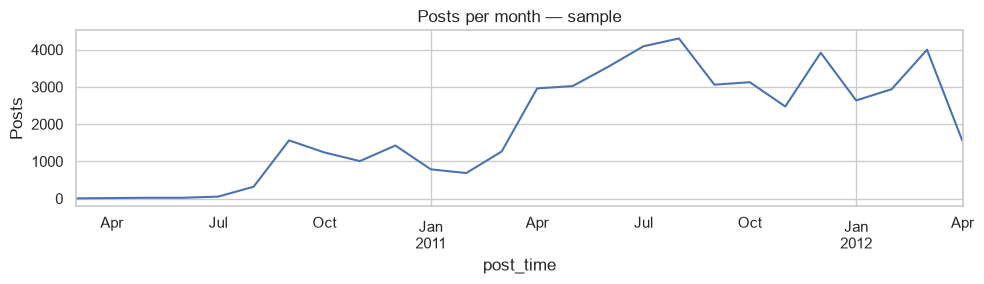

In [37]:
post_dates = pd.to_datetime(sample["post_time"], errors="coerce", utc=True)
monthly = post_dates.dt.to_period("M").value_counts().sort_index()
monthly.plot(figsize=(10, 3))
plt.title("Posts per month — sample")
plt.ylabel("Posts")
plt.tight_layout()
plt.show()

D. Relationships, correlations and redundancy
Investigate whether two variables describe similar behavior. Be careful: correlation does not imply causation.

D1 — Numeric correlation
Check whether follower and following counts are associated. Spearman correlation is useful for skewed counts.



In [38]:
display(numeric.corr(method="spearman").round(3))

,follower_count,following_count
follower_count,1.000,0.525
following_count,0.525,1.000


D2 — Correlation heatmap
Visualize numeric correlation values.

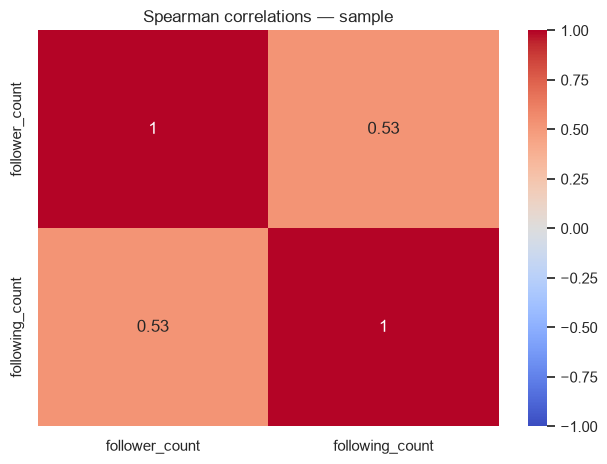

In [39]:
sns.heatmap(numeric.corr(method="spearman"), annot=True, vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Spearman correlations — sample")
plt.tight_layout()
plt.show()

D3 — Numeric pairwise relationship
Plot a subset to avoid overplotting; color by class to inspect possible differences.

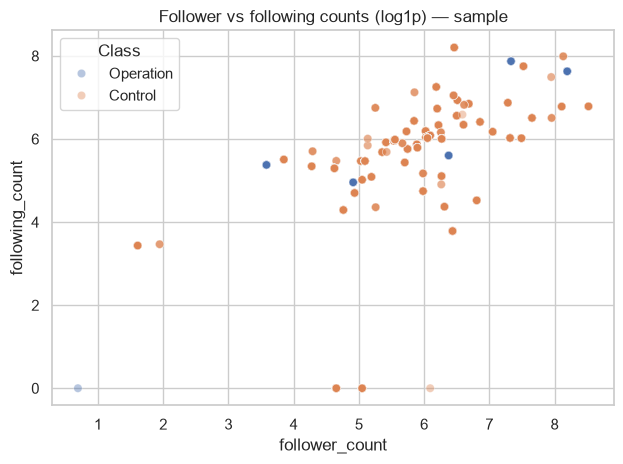

In [40]:
plot_data = numeric.join(labels.rename("Class")).dropna().head(3000)
sns.scatterplot(data=np.log1p(plot_data[["follower_count", "following_count"]].clip(lower=0)).join(plot_data["Class"]),
                x="follower_count", y="following_count", hue="Class", alpha=0.4)
plt.title("Follower vs following counts (log1p) — sample")
plt.tight_layout()
plt.show()

D4 — Country and class relationship
Compare the proportion of control and operation posts within each country; raw totals can be misleading.

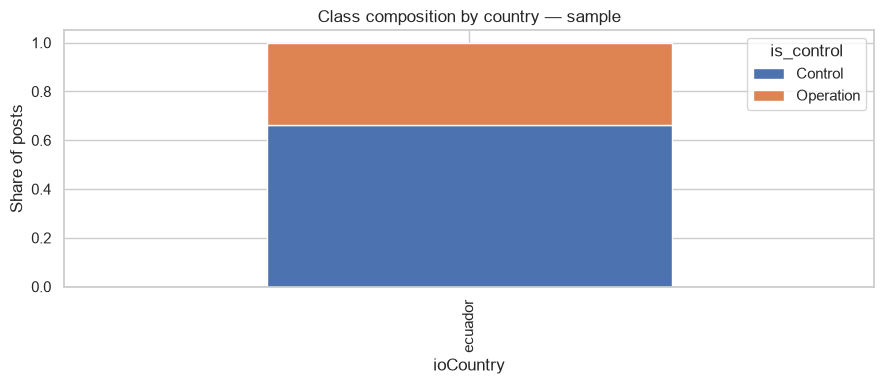

In [41]:
country_class = pd.crosstab(sample["ioCountry"], labels, normalize="index")
top = sample["ioCountry"].value_counts().head(10).index
country_class.reindex(top).plot.bar(stacked=True, figsize=(9, 4))
plt.ylabel("Share of posts")
plt.title("Class composition by country — sample")
plt.tight_layout()
plt.show()

D5 — Check possible redundant fields
Reply and repost IDs are related to interaction status. They are identifiers, not sensible direct numeric clustering features.

In [42]:
checks = pd.DataFrame({
    "has_reply_id": sample["in_reply_to_postid"].notna(),
    "has_repost_id": sample["reposted_postid"].notna(),
    "is_repost": reposts
})
display(checks.groupby("is_repost").mean().round(3))

,has_reply_id,has_repost_id
is_repost,,
0,0.257,0.0
1,0.000,1.0


E1 — Small preview of the user-level structure
This is a sample-based demonstration only, not the final user-profile table. It shows why we aggregate posts by accountid.

In [44]:
sample["follower_count"] = pd.to_numeric(
    sample["follower_count"], errors="coerce"
)

In [45]:
demo_users = sample.groupby("accountid", dropna=False).agg(
    post_count=("postid", "size"),
    country=("ioCountry", "first"),
    mean_followers=("follower_count", "mean")
)
display(demo_users.head())

,post_count,country,mean_followers
accountid,,,
0021f0f41422c32c9e3d7a96014bc6359c64d3214d,81,ecuador,795.0
005283930b48906c08bde2afc691cdec149b471ddd,15,ecuador,723.0
00bb8106568f13438c75eda8d2d9c48d7c9d8fb5e2,99,ecuador,1941.0
00d23f1596e776dd12e4c802844657720f6da1861e,62,ecuador,1153.0
018c14505e9de729947714ba8adaaa5b722a9074e0,3,ecuador,2975.0


E2 — Check the user-profile distribution

In [46]:
display(demo_users[["post_count", "mean_followers"]].describe().round(2))

,post_count,mean_followers
count,951.00,9.510000e+02
mean,52.58,1.437542e+06
std,338.54,3.136097e+07
min,1.00,-1.872970e+03
25%,7.00,2.220000e+02
50%,22.00,4.920000e+02
75%,56.00,1.209500e+03
max,7968.00,8.003534e+08
